In [ ]:
from IPython import display
import ultralytics
import cv2
import matplotlib.pyplot as plt
import os, glob, shutil

In [ ]:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

RUNS = os.path.abspath("runs")
os.makedirs("weights", exist_ok=True)
print("ผลลัพธ์จะเก็บที่:", RUNS)

ผลลัพธ์จะเก็บที่: C:\code\ImageProcessing\yolo\yolo_lab\final_dip\runs


In [ ]:
display.clear_output()
ultralytics.checks()

Ultralytics 8.4.174  Python-3.13.9 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-1334U)


Setup complete  (12 CPUs, 31.7 GB RAM, 266.3/280.1 GB disk)


In [ ]:
print(open("poly.yaml", encoding="utf-8").read())

names = ["airplane", "boat", "car", "motorcycle"]
for split in ["train", "val", "test"]:
    labels = glob.glob(f"datasets/yolo_poly/{split}/labels/*.txt")
    count = [0, 0, 0, 0]
    for f in labels:
        for line in open(f).read().splitlines():
            count[int(line.split()[0])] += 1
    detail = ", ".join(f"{n}={c}" for n, c in zip(names, count))
    print(f"{split:<5} : {len(labels):>3} ภาพ | object: {detail}")

# =============================================================
#  poly.yaml : ไฟล์ตั้งค่า dataset สำหรับ "Polygon" (Instance Segmentation)
#  ใช้กับโมเดล  yolo26n-seg.pt   (task = segment)
# =============================================================
# path  = โฟลเดอร์หลักของ dataset (relative กับโฟลเดอร์ที่รันคำสั่ง -> ให้รันจาก final_dip/)
# train/val/test = โฟลเดอร์ย่อยใน path  (ข้างในต้องมี images/ และ labels/)
path: ./datasets/yolo_poly
train: train
val: val
test: test

# จำนวนคลาส
nc: 4

# ชื่อคลาส  (ต้องใช้คีย์ "names" มี s นะ  ถ้าพิมพ์ "name" YOLO จะไม่อ่าน แล้วตั้งชื่อเป็น class0, class1 ...)
# ลำดับต้องตรงกับ CLASSES ใน scripts/02_anylabeling_to_yolo.py
names:
  0: airplane
  1: boat
  2: car
  3: motorcycle



train : 420 ภาพ | object: airplane=135, boat=153, car=161, motorcycle=154


val   : 120 ภาพ | object: airplane=43, boat=48, car=49, motorcycle=37


test  :  60 ภาพ | object: airplane=18, boat=35, car=28, motorcycle=16


ไฟล์: datasets/yolo_poly/train/labels\car_001.txt
2 0.196400 0.848105 0.193400 0.628863 0.193400 0.559475 0.230200 0.543732 0.242400 0.499125 0.256400 0.494752 0.259400 0.427405 0.239400 0.429738 0.231800 0.416327 0.239400 0.400583 0.250200 0.405248 0.254800 0.407289 0.267000 0.391837 0.268600 0.326822 0.260800 0.295627 0.280800 0.264140 0.310000 0 ...
object คลาส 2 มี 51 จุด


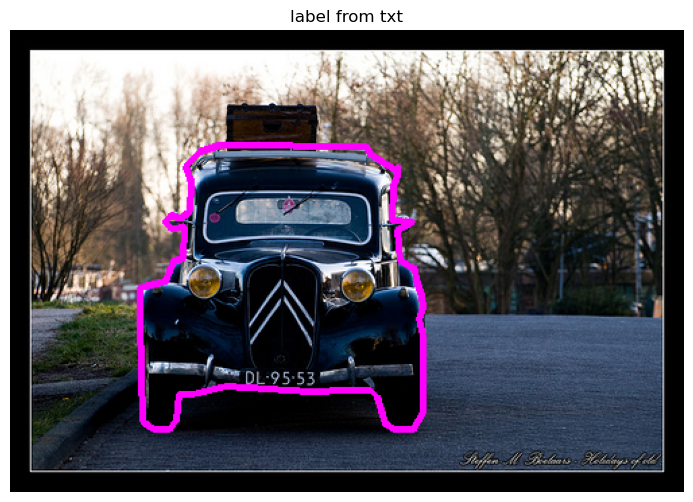

In [ ]:
import numpy as np
img_path = sorted(glob.glob("datasets/yolo_poly/train/images/car_*.jpg"))[0]
lbl_path = img_path.replace("images", "labels").replace(".jpg", ".txt")
print("ไฟล์:", lbl_path)
print(open(lbl_path).read()[:300], "...")

im = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
h, w = im.shape[:2]
for line in open(lbl_path).read().splitlines():
    v = list(map(float, line.split()))
    pts = (np.array(v[1:]).reshape(-1, 2) * [w, h]).astype(np.int32)
    cv2.polylines(im, [pts.reshape(-1, 1, 2)], True, (255, 0, 255), 3)
    print(f"object คลาส {int(v[0])} มี {len(pts)} จุด")
plt.figure(figsize=(9, 6)); plt.imshow(im); plt.title("label from txt"); plt.axis("off"); plt.show()

In [ ]:
model = ultralytics.YOLO('yolo26n-seg.yaml').load('yolo26n-seg.pt')
print("จำนวนคลาสที่โมเดลรู้จักตอนนี้:", len(model.names))

Transferred 844/844 items from pretrained weights


จำนวนคลาสที่โมเดลรู้จักตอนนี้: 80


0: 576x640 1 4, 180.4ms


Speed: 5.7ms preprocess, 180.4ms inference, 14.6ms postprocess per image at shape (1, 3, 576, 640)


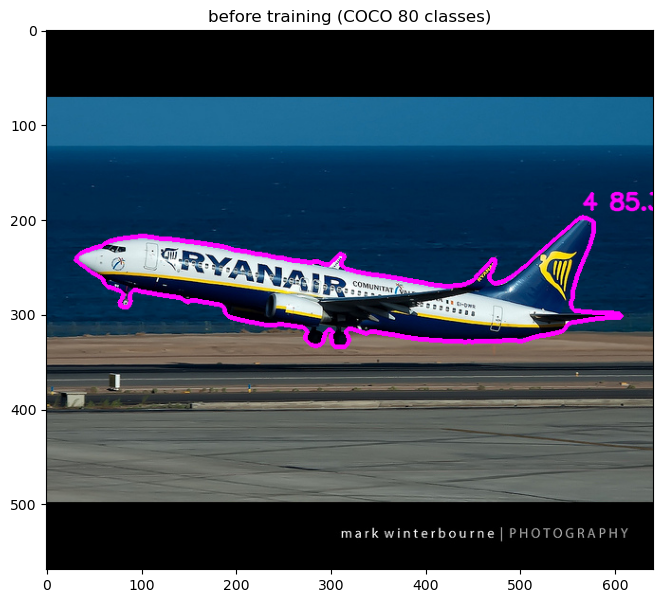

In [ ]:
path = sorted(glob.glob('datasets/yolo_poly/test/images/*.jpg'))[0]
im_src = cv2.imread(path)
result = model.predict(source=im_src)
im_result = cv2.cvtColor(im_src, cv2.COLOR_BGR2RGB)

if result[0].masks is not None:
    for i in range(len(result[0].masks.xy)):
        class_id = int(result[0].boxes.cls[i].item())
        conf = round(result[0].boxes.conf[i].item()*100, 2)
        x = result[0].masks.xy[i].astype(int)
        pts = x.reshape((-1, 1, 2))
        im_result = cv2.polylines(im_result, [pts], isClosed=True, color=(255, 0, 255), thickness=3)
        im_result = cv2.putText(im_result, f"{result[0].names[class_id]} {conf}%", (int(x[0][0]), max(int(x[0][1]) - 8, 20)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 255), 2, cv2.LINE_AA)

plt.figure(figsize=(10, 7))
plt.imshow(im_result)
plt.title("before training (COCO 80 classes)")
plt.show()

In [ ]:
model = ultralytics.YOLO("yolo26n-seg.pt")
model.train(data="poly.yaml", epochs=20, imgsz=512, batch=16, patience=15, workers=2,
            device="cpu", seed=42, project=RUNS, name="poly", exist_ok=True)

shutil.copy("runs/poly/weights/best.pt", "weights/poly_best.pt")
print("saved -> weights/poly_best.pt")

New https://pypi.org/project/ultralytics/8.4.193 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.174  Python-3.13.9 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-1334U)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=poly.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=poly, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=15, perspective=0.0, plots=True, pose=12.0, pretrained=True, p

Overriding model.yaml nc=80 with nc=4



                   from  n    params  module                                       arguments                     


...

                   car         30         49       0.73      0.663      0.766      0.566      0.762      0.612      0.725      0.472


            motorcycle         30         37      0.911      0.831      0.908      0.595      0.933      0.811      0.889       0.48


Speed: 1.1ms preprocess, 45.6ms inference, 0.0ms loss, 4.6ms postprocess per image


Results saved to C:\code\ImageProcessing\yolo\yolo_lab\final_dip\runs\poly


saved -> weights/poly_best.pt


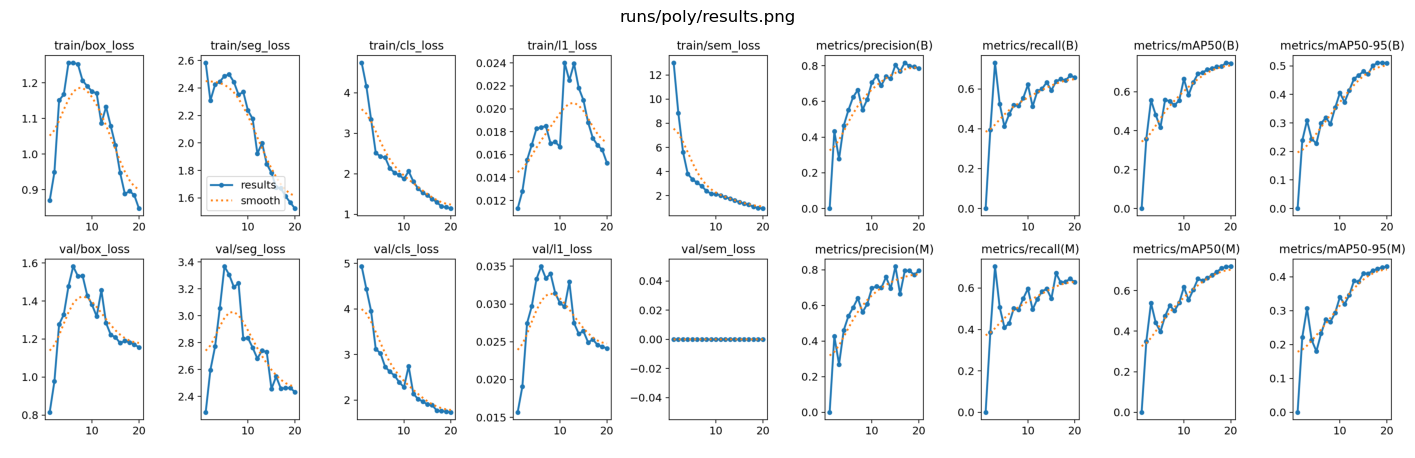

In [ ]:
img = cv2.cvtColor(cv2.imread("runs/poly/results.png"), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(18, 9)); plt.imshow(img); plt.axis("off"); plt.title("runs/poly/results.png"); plt.show()

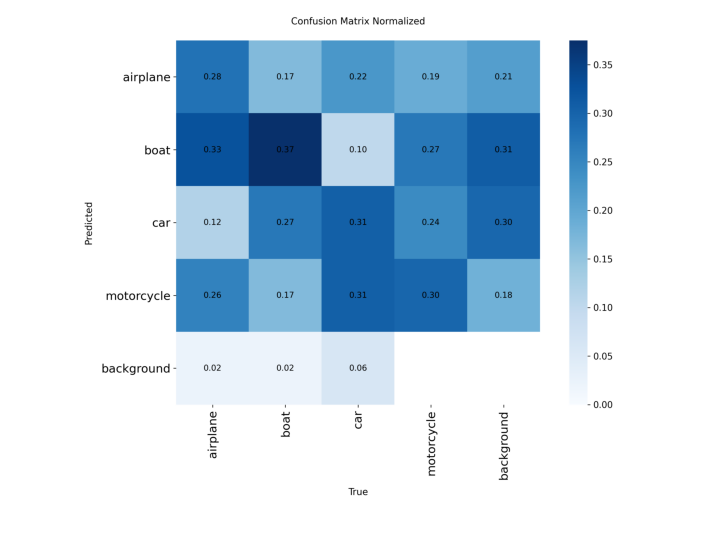

In [ ]:
img = cv2.cvtColor(cv2.imread("runs/poly/confusion_matrix_normalized.png"), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(9, 9)); plt.imshow(img); plt.axis("off"); plt.show()

คลาสที่โมเดลรู้จักตอนนี้: {0: 'airplane', 1: 'boat', 2: 'car', 3: 'motorcycle'}


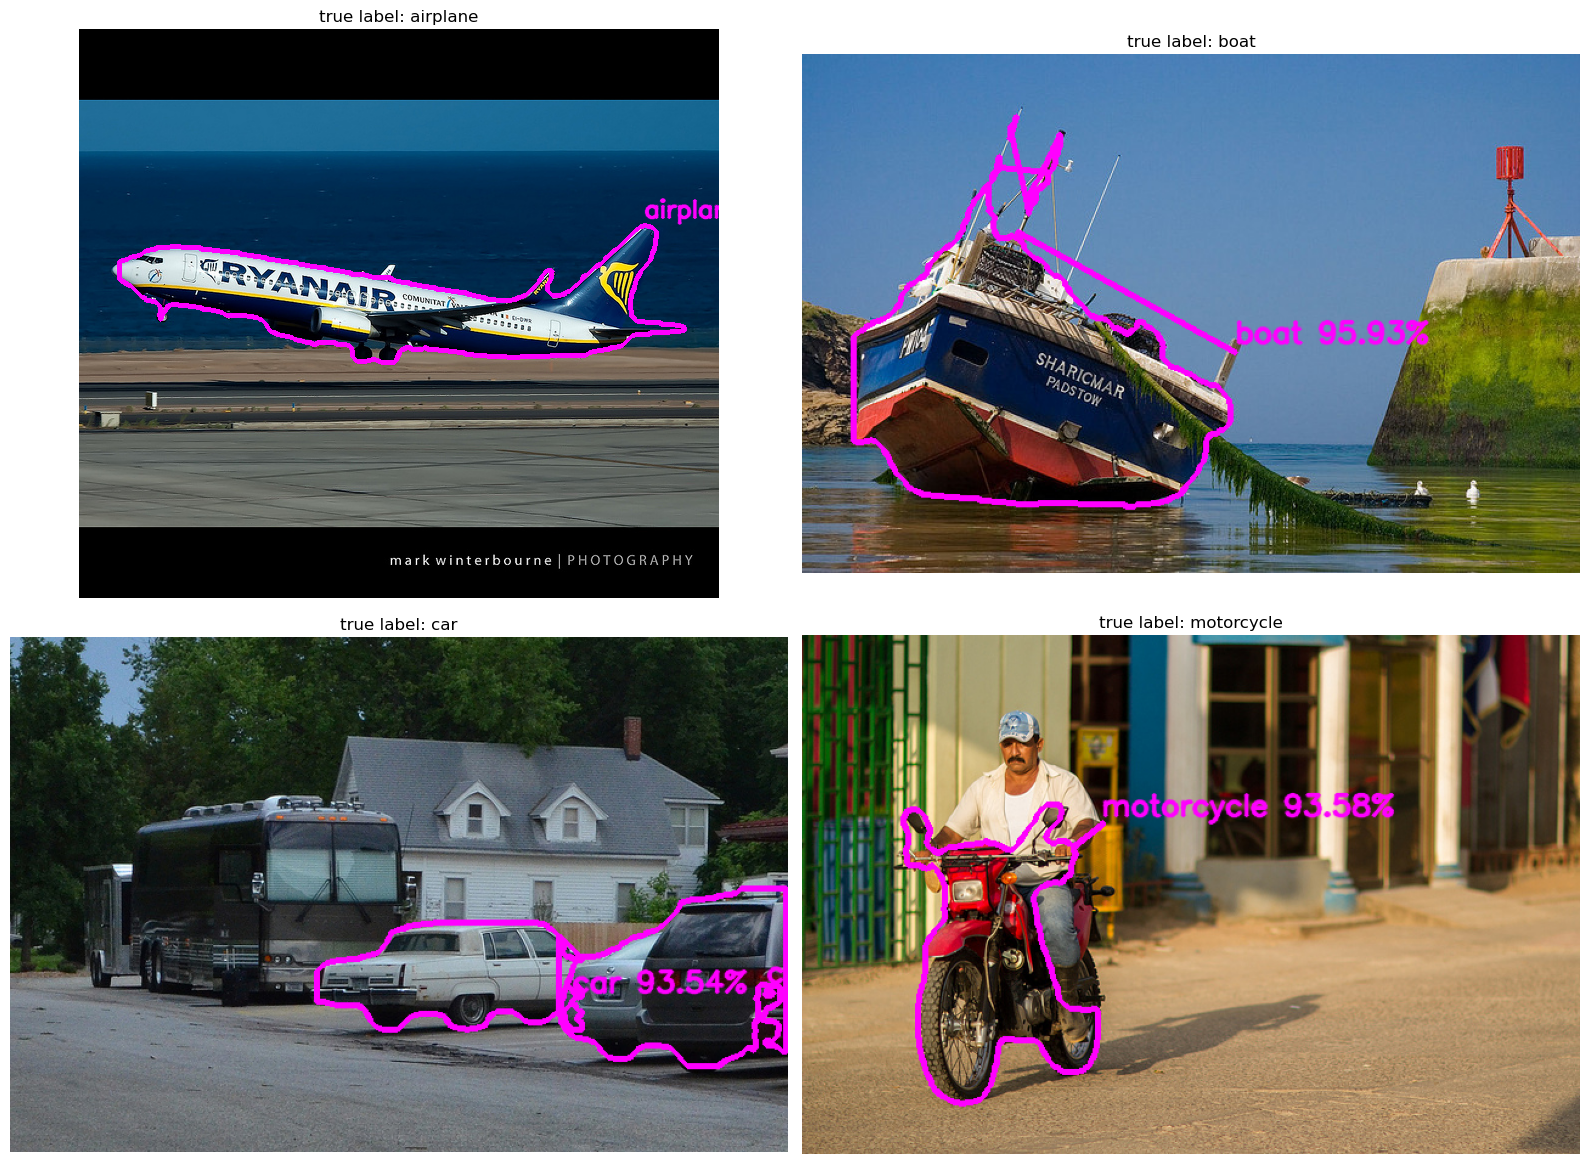

In [ ]:
model = ultralytics.YOLO("weights/poly_best.pt")
print("คลาสที่โมเดลรู้จักตอนนี้:", model.names)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, cls in zip(axes.flat, ["airplane", "boat", "car", "motorcycle"]):
    path = sorted(glob.glob(f'datasets/yolo_poly/test/images/{cls}_*.jpg'))[0]
    im_src = cv2.imread(path)
    result = model.predict(source=im_src, imgsz=512, conf=0.25, verbose=False)
    im_result = cv2.cvtColor(im_src, cv2.COLOR_BGR2RGB)

    if result[0].masks is not None:
        for i in range(len(result[0].masks.xy)):
            class_id = int(result[0].boxes.cls[i].item())
            conf = round(result[0].boxes.conf[i].item()*100, 2)
            x = result[0].masks.xy[i].astype(int)
            pts = x.reshape((-1, 1, 2))
            im_result = cv2.polylines(im_result, [pts], isClosed=True, color=(255, 0, 255), thickness=3)
            im_result = cv2.putText(im_result, f"{result[0].names[class_id]} {conf}%", (int(x[0][0]), max(int(x[0][1]) - 8, 20)),
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 255), 2, cv2.LINE_AA)

    ax.imshow(im_result); ax.set_title(f"true label: {cls}"); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
rows = []
for f in sorted(glob.glob("datasets/yolo_poly/test/images/*.jpg")):
    r = model.predict(f, imgsz=512, conf=0.25, verbose=False)[0]
    true = os.path.basename(f).rsplit("_", 1)[0]
    pred = r.names[int(r.boxes.cls[r.boxes.conf.argmax()])] if len(r.boxes) else "(ไม่เจอ)"
    rows.append({"true": true, "pred": pred, "correct": true == pred})
df = pd.DataFrame(rows)
print(f"ทายถูก {df.correct.sum()} / {len(df)} ภาพ  ({df.correct.mean()*100:.1f}%)")
pd.crosstab(df["true"], df["pred"], rownames=["จริง"], colnames=["ทาย"])

ทายถูก 55 / 60 ภาพ  (91.7%)


ทาย,(ไม่เจอ),airplane,boat,car,motorcycle
จริง,,,,,
airplane,0,15,0,0,0
boat,1,0,13,1,0
car,2,0,0,13,0
motorcycle,1,0,0,0,14


Results saved to C:\code\ImageProcessing\yolo\yolo_lab\final_dip\runs\predict_poly


runs/predict_poly/ : 60 ภาพ


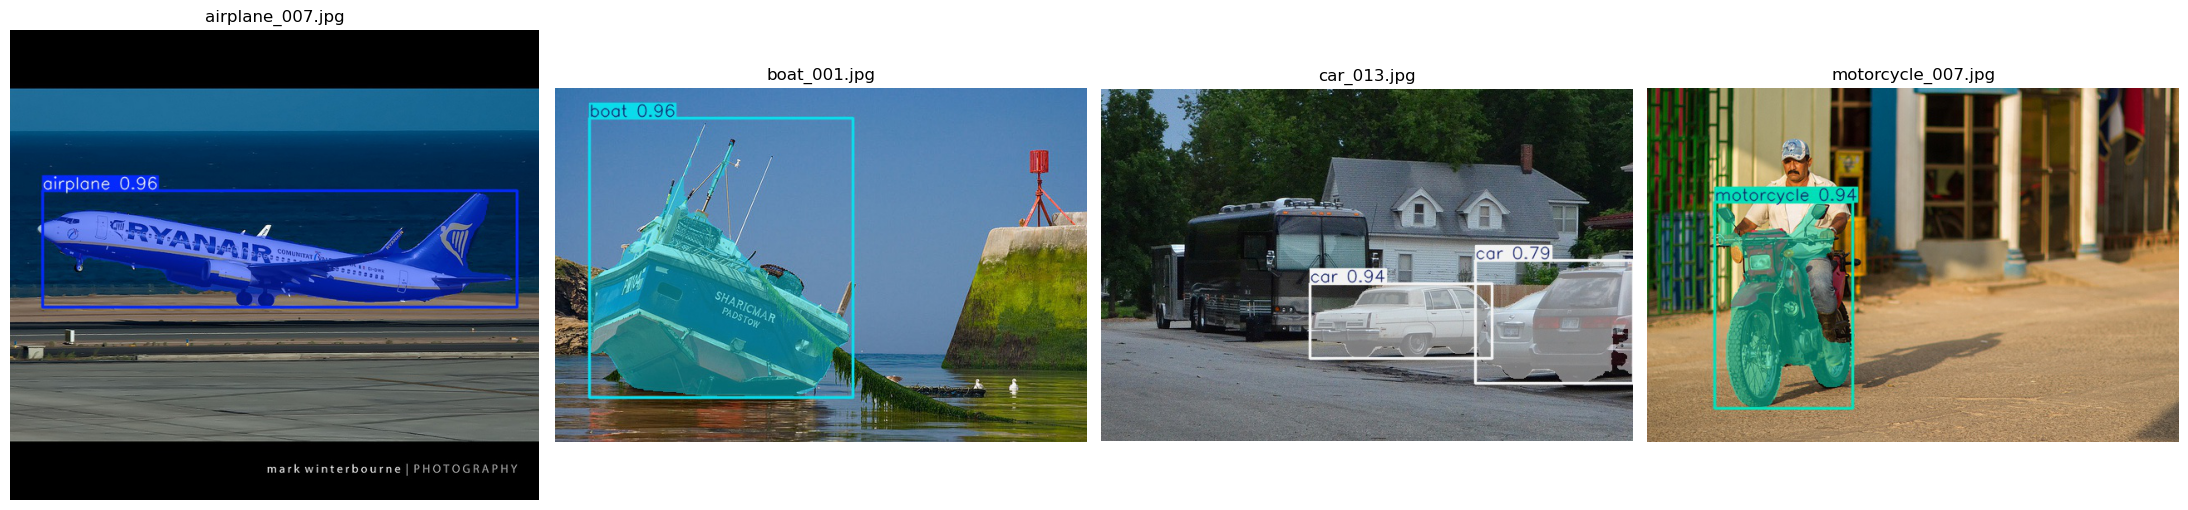

In [ ]:
model.predict(source="datasets/yolo_poly/test/images", imgsz=512, conf=0.25, save=True,
              project=RUNS, name="predict_poly", exist_ok=True, verbose=False)
saved = sorted(glob.glob("runs/predict_poly/*.jpg"))
print("runs/predict_poly/ :", len(saved), "ภาพ")

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, f in zip(axes, saved[::15]):
    ax.imshow(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)); ax.set_title(os.path.basename(f)); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
os.makedirs("web/frontend/models", exist_ok=True)
onnx_path = ultralytics.YOLO("weights/poly_best.pt").export(format="onnx", imgsz=512, simplify=True)
shutil.move(onnx_path, "web/frontend/models/poly.onnx")

for f in ["weights/poly_best.pt", "web/frontend/models/poly.onnx"]:
    print(f"{f:<34} {os.path.getsize(f) / 1e6:.1f} MB")

Ultralytics 8.4.174  Python-3.13.9 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-1334U)


YOLO26n-seg summary (fused): 136 layers, 2,689,664 parameters, 0 gradients, 5.8 GFLOPs



PyTorch: starting from 'weights\poly_best.pt' with input shape (1, 3, 512, 512) BCHW and output shape(s) ((1, 40, 5376), (1, 32, 128, 128)) (6.2 MB)



ONNX: starting export with onnx 1.23.2 opset 18...


ONNX: slimming with onnxslim 0.1.98...


ONNX: export success  3.5s, saved as 'weights\poly_best.onnx' (10.5 MB)



Export complete (3.9s)
Results saved to C:\code\ImageProcessing\yolo\yolo_lab\final_dip\weights\poly_best.onnx
Predict:         yolo predict task=segment model=weights\poly_best.onnx imgsz=512 
Validate:        yolo val task=segment model=weights\poly_best.onnx imgsz=512 data=poly.yaml  
Visualize:       https://netron.app


weights/poly_best.pt               6.5 MB
web/frontend/models/poly.onnx      11.0 MB


In [ ]:
import onnxruntime as ort
sess = ort.InferenceSession("web/frontend/models/poly.onnx")
print("input :", [(i.name, i.shape) for i in sess.get_inputs()])
print("output:", [(o.name, o.shape) for o in sess.get_outputs()])

path = "datasets/yolo_poly/test/images/motorcycle_007.jpg"
for f in ["weights/poly_best.pt", "web/frontend/models/poly.onnx"]:
    r = ultralytics.YOLO(f, task="segment").predict(path, imgsz=512, conf=0.25, verbose=False)[0]
    print(f"{os.path.basename(f):<14} ->", [(r.names[int(c)], round(float(s), 3)) for c, s in zip(r.boxes.cls, r.boxes.conf)])

input : [('images', [1, 3, 512, 512])]
output: [('output0', [1, 40, 5376]), ('output1', [1, 32, 128, 128])]


poly_best.pt   -> [('motorcycle', 0.936)]
Loading web/frontend/models/poly.onnx for ONNX Runtime inference...


Using ONNX Runtime 1.31.0 with CPUExecutionProvider


poly.onnx      -> [('motorcycle', 0.94)]


In [ ]:
import sys
DEPLOY = False
if DEPLOY:
    !{sys.executable} scripts/05_deploy_huggingface.py --space witthaya22/final-dip
else:
    print("ยังไม่ deploy (ตั้ง DEPLOY = True แล้วรันใหม่)")
print("เว็บ: https://witthaya22-final-dip.static.hf.space")